In [43]:
import openseespy.opensees as ops
import opsvis as opsv
import matplotlib.pyplot as plt
import numpy as np

In [44]:
m=1
mm=0.001*m
pa=1
kpa=1000*pa
mpa=1000*kpa
gpa=1000*mpa

In [45]:
# def getsection():

ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 3)

In [46]:
# define steel material
mattag=1
fy=350*mpa
E=200*gpa
b=0.001
ops.uniaxialMaterial('Steel02', mattag, fy, E, b)

# define concrete material
fpc=-30*mpa
epsc0=-0.002
fpcu=-20*mpa
epsu=-0.008
lamda=0.1
ft=3*mpa
ets=150*mpa
ops.uniaxialMaterial('Concrete02', 2, fpc, epsc0, fpcu, epsu, lamda, ft, ets)
ops.uniaxialMaterial('Concrete02',3,-25*mpa, -0.002,-15*mpa,-0.006,0.1,2*mpa,100*mpa)

In [47]:
ops.node(1, 0.0,0.0)
ops.node(2, 0.0,1)
ops.node(3, 0.0,2)
ops.node(4, 0.0,3)
ops.fix(1, 1, 1, 1)

In [48]:
# #section defination
# # Bd=400*mm
# # D=600*mm
confinedconcretetag=2
unconfinedconcretetag=3
numsubdiv=10
sectag=1
ops.section('Fiber', sectag, '-GJ', 1.0e6)
ops.patch('rect',confinedconcretetag,numsubdiv,1,-300*mm/2,-450*mm/2,300*mm/2,450*mm/2) #CONFINED CONCRETE


ops.patch('quad',unconfinedconcretetag,1,1,300*mm/2,450*mm/2,-300*mm/2,450*mm/2,-400*mm/2,600*mm/2,400*mm/2,600*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,400*mm/2,600*mm/2,300*mm/2,450*mm/2,300*mm/2,-450*mm/2,400*mm/2,-600*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,300*mm/2,450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,-600*mm/2,400*mm/2,-600*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-300*mm/2,-450*mm/2,-300*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,-600*mm/2) #unconfined concrete
ops.layer('straight', mattag, 3,300*mm**2,300*mm/2,450*mm/2,-300*mm/2,450*mm/2) #steel layer
ops.layer('straight', mattag, 3,300*mm**2,300*mm/2,-450*mm/2,-300*mm/2,-450*mm/2) #steel layer

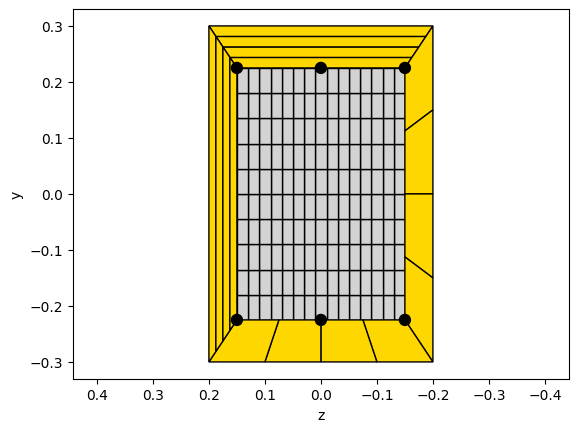

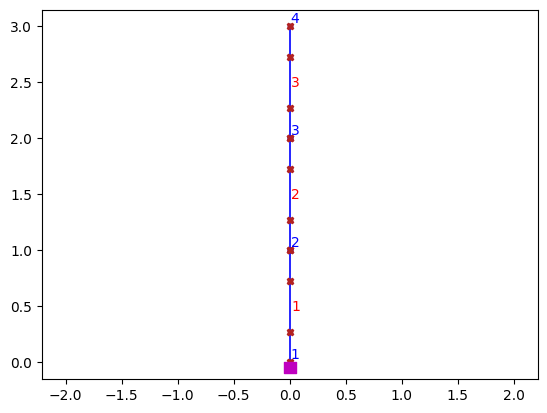

In [49]:
#geometry transformation
ops.geomTransf('PDelta', 1)
ops.beamIntegration('Lobatto', 1, sectag, 4)
mass=6000

ops.element('forceBeamColumn', 1, 1, 2, 1, 1,'-mass',mass) #ops.element('forceBeamColumn', eleTag, iNode, jNode, transfTag, integrationTag, '-mass', massDensity)
ops.element('forceBeamColumn', 2, 2, 3, 1, 1,'-mass',mass)
ops.element('forceBeamColumn', 3, 3, 4, 1, 1,'-mass',mass)

# def plot():
# fib_sec_1 = [
#     ['section', 'Fiber', 1, '-GJ', 1.0e6],
#     ['patch','rect',confinedconcretetag,numsubdiv,1,-300*mm/2,-450*mm/2,300*mm/2,450*mm/2],
#     ['patch','quad',unconfinedconcretetag,1,2,-300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2,600*mm/2,-400*mm/2,600*mm/2],   # top cover 
#     ['patch','quad',unconfinedconcretetag,1,5,400*mm/2,600*mm/2,300*mm/2,450*mm/2,300*mm/2,-450*mm/2,400*mm/2,-600*mm/2],  # right cover
#     ['patch','quad',unconfinedconcretetag,2,5,-400*mm/2,-600*mm/2,-300*mm/2,-450*mm/2, -300*mm/2, 450*mm/2,-400*mm/2, 600*mm/2], # left cover
#     ['patch','quad',unconfinedconcretetag,1,5,-300*mm/2,-450*mm/2,300*mm/2,-450*mm/2,400*mm/2,600*mm/2,-400*mm/2,-600*mm/2], # bottom cover
#     ['layer', 'straight', mattag, 3, 300*mm**2, 300*mm/2,450*mm/2,-300*mm/2,450*mm/2],
#     ['layer', 'straight', mattag, 3, 300*mm**2, 300*mm/2,-450*mm/2,-300*mm/2,-450*mm/2]
# ]
fib_sec_1 = [
    ['section', 'Fiber', 1, '-GJ', 1.0e6],

    # Confined concrete core: 300 x 450 mm
    ['patch', 'rect', confinedconcretetag, numsubdiv, 15,
     -450*mm/2, -300*mm/2,
      450*mm/2,  300*mm/2],

    # Top cover
    ['patch', 'quad', unconfinedconcretetag, 4, 1,
     450*mm/2, -300*mm/2,
      600*mm/2, -400*mm/2,
      600*mm/2, 400*mm/2,
     450*mm/2, 300*mm/2],

    # Right cover
    ['patch', 'quad', unconfinedconcretetag, 4, 1,
      450*mm/2, -300*mm/2,
      -450*mm/2, -300*mm/2,
      -600*mm/2,  -400*mm/2,
      600*mm/2,  -400*mm/2],

    # Bottom cover
    ['patch', 'quad', unconfinedconcretetag, 4, 1,
     -450*mm/2, -300*mm/2,
      -450*mm/2, 300*mm/2,
      -600*mm/2, 400*mm/2,
     -600*mm/2, -400*mm/2],

    # Left cover
    ['patch', 'quad', unconfinedconcretetag, 4, 1,
     -600*mm/2, 400*mm/2,
     -450*mm/2, 300*mm/2,
     450*mm/2,  300*mm/2,
     600*mm/2,  400*mm/2],

    # Top reinforcement
    ['layer', 'straight', mattag, 3, 300*mm**2,
      450*mm/2, 300*mm/2,
     450*mm/2, -300*mm/2],

    # Bottom reinforcement
    ['layer', 'straight', mattag, 3, 300*mm**2,
      -450*mm/2, 300*mm/2,
     -450*mm/2, -300*mm/2]
] 
             
matcolor = ['r', 'lightgrey', 'gold', 'w', 'w', 'w']
opsv.plot_fiber_section(fib_sec_1, matcolor=matcolor)
plt.axis('equal')
opsv.plot_model()
plt.show()
